In [4]:
# Interpretable Postpartum Anxiety Symptom Screening Using a Hybrid Ensemble and Explainable AI

# Task 1: Import libraries
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)            # hide library update notices
warnings.filterwarnings("ignore", message="IProgress not found")     # hide a progress-bar notice

import lime.lime_tabular
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy import stats
from scipy.stats import spearmanr
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, balanced_accuracy_score, brier_score_loss,
                             make_scorer, matthews_corrcoef, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.svm import SVC

ModuleNotFoundError: No module named 'lime'

In [ ]:
# Task 2: Settings
DATA_FILE = "../data/raw/postpartum_depression.csv"
RESULTS_FOLDER = Path("../results/final")
RESULTS_FOLDER.mkdir(parents=True, exist_ok=True)

TARGET = "Feeling anxious"
SEED = 42                       # the hybrid design was chosen earlier on seeds 7 and 2026
PROPOSED = "Hybrid Ensemble (proposed)"
BLUE, GREY = "#0072B2", "#B0B0B0"

In [ ]:
# Task 3: Load the dataset (the CSV file is only read, never changed)
raw = pd.read_csv(DATA_FILE)

In [ ]:
# Task 4: Check for duplicate rows
answers = raw.drop(columns="Timestamp")
print("Duplicate rows:", answers.duplicated().sum(), "of", len(answers))

Duplicate rows: 1177 of 1503


In [ ]:
# Task 5: Remove duplicate rows (done before any split, so no copy can leak into a test set)
unique_rows = answers.drop_duplicates().reset_index(drop=True)

In [ ]:
# Task 6: Features (X) and target (y)
X = unique_rows.drop(columns=TARGET).astype(object)
y = (unique_rows[TARGET] == "Yes").astype(int).to_numpy()

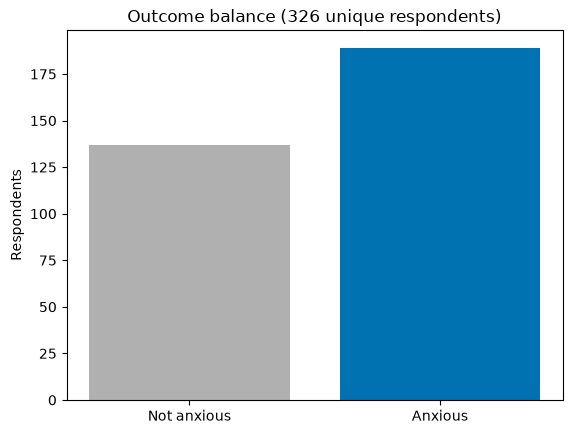

In [ ]:
# Task 7: Figure - how many respondents are anxious?
counts = unique_rows[TARGET].value_counts()
plt.bar(["Not anxious", "Anxious"], [counts["No"], counts["Yes"]], color=[GREY, BLUE])
plt.ylabel("Respondents")
plt.title("Outcome balance (326 unique respondents)")
plt.savefig(RESULTS_FOLDER / "fig01_class_balance.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Task 8: Preprocessing - fill missing answers and one-hot encode (learned inside each training fold)
def preprocessing():
    return make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))

In [ ]:
# Task 9: Algorithm 1 - Logistic Regression
def logistic_regression():
    return make_pipeline(preprocessing(), LogisticRegression(max_iter=2000))

In [ ]:
# Task 10: Algorithm 2 - Random Forest
def random_forest():
    return make_pipeline(preprocessing(), RandomForestClassifier(
        n_estimators=300, max_depth=6, min_samples_leaf=3, random_state=SEED))

In [ ]:
# Task 11: Algorithm 3 - Extra Trees
def extra_trees():
    return make_pipeline(preprocessing(), ExtraTreesClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=3, random_state=SEED))

In [ ]:
# Task 12: Algorithm 4 - SVM (calibrated so it gives probabilities)
def svm():
    return make_pipeline(preprocessing(), CalibratedClassifierCV(SVC(C=1), ensemble=False, cv=5))

In [ ]:
# Task 13: Algorithm 5 - proposed Hybrid Ensemble (average of the probabilities of RF, Extra Trees and SVM)
def hybrid_ensemble():
    return VotingClassifier([("rf", random_forest()), ("et", extra_trees()), ("svm", svm())], voting="soft")

In [ ]:
# Task 14: Put the five algorithms together
models = {
    "Logistic Regression": logistic_regression(),
    "Random Forest": random_forest(),
    "Extra Trees": extra_trees(),
    "SVM": svm(),
    PROPOSED: hybrid_ensemble(),
}

In [ ]:
# Task 15: Evaluation metrics
SCORING = {
    "balanced_accuracy": "balanced_accuracy",
    "accuracy": "accuracy",
    "sensitivity": "recall",
    "specificity": make_scorer(recall_score, pos_label=0),
    "f1": "f1",
    "mcc": make_scorer(matthews_corrcoef),
    "roc_auc": "roc_auc",
}

In [ ]:
# Task 16: Train and test every model - 5-fold cross-validation repeated 10 times (50 test folds)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)

cv_results = {}
for name, model in models.items():
    cv_results[name] = cross_validate(model, X, y, cv=cv, scoring=SCORING,
                                      return_train_score=True, n_jobs=-1)

In [ ]:
# Task 17: Test results table (mean of 50 test folds)
rows = []
for name in models:
    row = {"model": name}
    for metric in SCORING:
        row[metric] = cv_results[name]["test_" + metric].mean()
    rows.append(row)

test_results = pd.DataFrame(rows).set_index("model").round(3)
test_results.to_csv(RESULTS_FOLDER / "test_results.csv")

In [ ]:
# Task 18: 95% confidence interval of balanced accuracy
# The Nadeau-Bengio correction makes the interval wider because training sets overlap in CV.
def corrected_se(values):
    n_test, n_train = len(y) / 5, len(y) - len(y) / 5
    return np.sqrt((1 / len(values) + n_test / n_train) * np.var(values, ddof=1))


rows = []
for name in models:
    values = cv_results[name]["test_balanced_accuracy"]
    margin = 1.96 * corrected_se(values)
    rows.append({"model": name, "mean": values.mean(), "lower_95": values.mean() - margin,
                 "upper_95": values.mean() + margin})

confidence = pd.DataFrame(rows).set_index("model").round(3)
confidence.to_csv(RESULTS_FOLDER / "balanced_accuracy_ci.csv")
confidence

,mean,lower_95,upper_95
model,,,
Logistic Regression,0.730,0.668,0.792
Random Forest,0.771,0.719,0.823
Extra Trees,0.760,0.711,0.809
SVM,0.767,0.716,0.818
Hybrid Ensemble (proposed),0.772,0.721,0.823


In [ ]:
# Task 19: Training vs testing balanced accuracy (a big gap means overfitting)
rows = []
for name in models:
    train = cv_results[name]["train_balanced_accuracy"].mean()
    test = cv_results[name]["test_balanced_accuracy"].mean()
    rows.append({"model": name, "train": train, "test": test, "gap": train - test})

train_test = pd.DataFrame(rows).set_index("model").round(3)
train_test.to_csv(RESULTS_FOLDER / "train_vs_test.csv")
train_test

,train,test,gap
model,,,
Logistic Regression,0.776,0.730,0.045
Random Forest,0.846,0.771,0.075
Extra Trees,0.931,0.760,0.171
SVM,0.862,0.767,0.096
Hybrid Ensemble (proposed),0.874,0.772,0.102


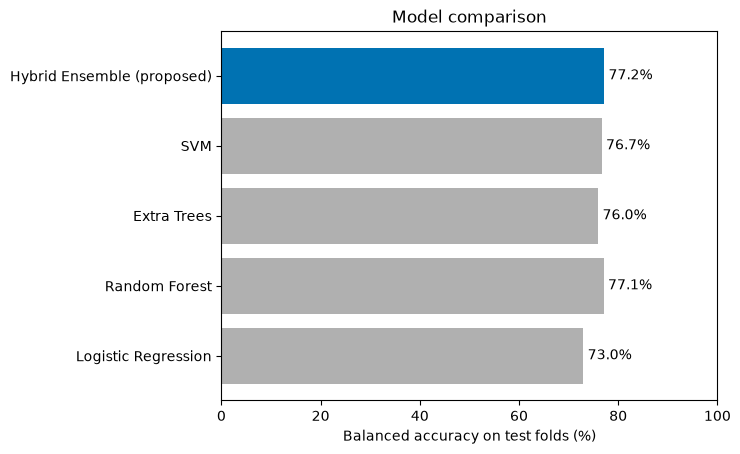

In [ ]:
# Task 20: Figure - test balanced accuracy of each model
colors = []
for name in models:
    if name == PROPOSED:
        colors.append(BLUE)
    else:
        colors.append(GREY)

bars = plt.barh(list(models), test_results["balanced_accuracy"] * 100, color=colors)
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.xlim(0, 100)
plt.xlabel("Balanced accuracy on test folds (%)")
plt.title("Model comparison")
plt.savefig(RESULTS_FOLDER / "fig02_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

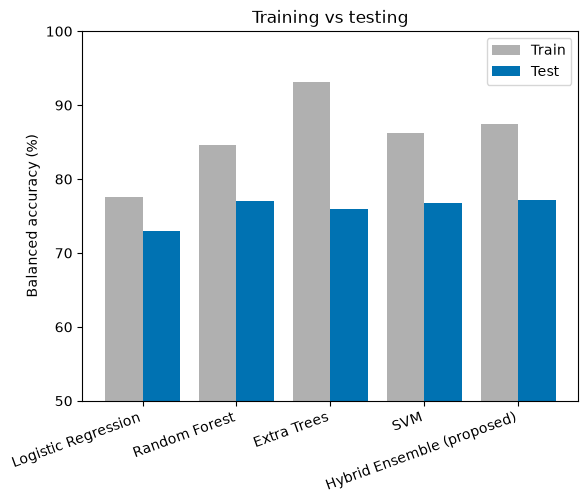

In [ ]:
# Task 21: Figure - training vs testing balanced accuracy
positions = np.arange(len(train_test))
plt.bar(positions - 0.2, train_test["train"] * 100, width=0.4, color=GREY, label="Train")
plt.bar(positions + 0.2, train_test["test"] * 100, width=0.4, color=BLUE, label="Test")
plt.xticks(positions, train_test.index, rotation=20, ha="right")
plt.ylabel("Balanced accuracy (%)")
plt.ylim(50, 100)
plt.legend()
plt.title("Training vs testing")
plt.savefig(RESULTS_FOLDER / "fig03_train_vs_test.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Task 22: Statistical test - is the Hybrid Ensemble significantly different from each other model?
# Corrected paired t-test on the same 50 folds; Bonferroni correction because we make 4 comparisons
proposed_scores = cv_results[PROPOSED]["test_balanced_accuracy"]

rows = []
for name in models:
    if name == PROPOSED:
        continue
    difference = proposed_scores - cv_results[name]["test_balanced_accuracy"]
    t = difference.mean() / corrected_se(difference)
    p = 2 * stats.t.sf(abs(t), df=len(difference) - 1)
    p_corrected = min(p * 4, 1)
    rows.append({"compared_with": name, "difference": difference.mean(), "p_value": p,
                 "p_corrected": p_corrected, "significant": p_corrected < 0.05})

tests = pd.DataFrame(rows).round(4)
tests.to_csv(RESULTS_FOLDER / "statistical_tests.csv", index=False)
tests

,compared_with,difference,p_value,p_corrected,significant
0,Logistic Regression,0.0418,0.0383,0.153,False
1,Random Forest,0.0012,0.8785,1.000,False
2,Extra Trees,0.0119,0.2761,1.000,False
3,SVM,0.0053,0.4692,1.000,False


In [ ]:
# Task 23: Overall ranking (average of the balanced-accuracy rank and the ROC-AUC rank)
ranking = test_results[["balanced_accuracy", "roc_auc"]].copy()
rank_balanced_accuracy = ranking["balanced_accuracy"].rank(ascending=False)
rank_roc_auc = ranking["roc_auc"].rank(ascending=False)
ranking["rank"] = (rank_balanced_accuracy + rank_roc_auc) / 2
ranking = ranking.sort_values("rank")
ranking.to_csv(RESULTS_FOLDER / "ranking.csv")
print("Best overall model:", ranking.index[0])

Best overall model: Hybrid Ensemble (proposed)


In [ ]:
# Task 24: Out-of-fold probabilities (every respondent predicted once, by a model that never saw them)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = pd.DataFrame()
for name, model in models.items():
    probabilities = cross_val_predict(model, X, y, cv=cv5, method="predict_proba", n_jobs=-1)
    oof[name] = probabilities[:, 1]

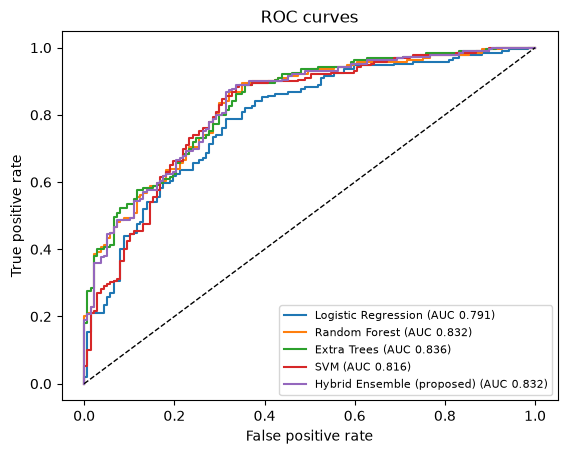

In [ ]:
# Task 25: Figure - ROC curves
for name in models:
    fpr, tpr, thresholds = roc_curve(y, oof[name])
    auc = roc_auc_score(y, oof[name])
    plt.plot(fpr, tpr, label=name + " (AUC " + str(round(auc, 3)) + ")")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves")
plt.legend(fontsize=8)
plt.savefig(RESULTS_FOLDER / "fig04_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

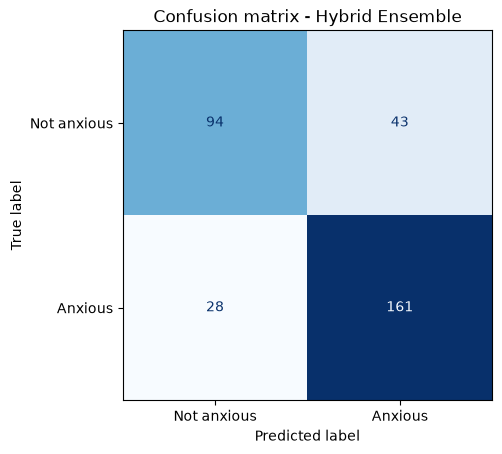

In [ ]:
# Task 26: Figure - confusion matrix of the proposed model
ConfusionMatrixDisplay.from_predictions(y, oof[PROPOSED] >= 0.5, display_labels=["Not anxious", "Anxious"],
                                        cmap="Blues", colorbar=False)
plt.title("Confusion matrix - Hybrid Ensemble")
plt.savefig(RESULTS_FOLDER / "fig05_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

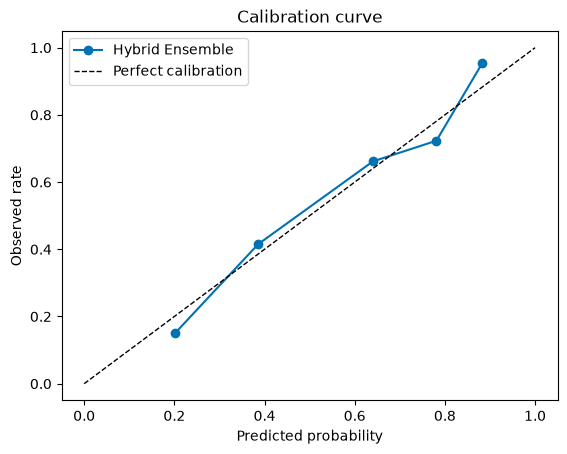

Brier score: 0.163 (lower is better)


In [ ]:
# Task 27: Figure - calibration curve of the proposed model (are the probabilities trustworthy?)
observed, predicted = calibration_curve(y, oof[PROPOSED], n_bins=5, strategy="quantile")
plt.plot(predicted, observed, marker="o", color=BLUE, label="Hybrid Ensemble")
plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Perfect calibration")
plt.xlabel("Predicted probability")
plt.ylabel("Observed rate")
plt.title("Calibration curve")
plt.legend()
plt.savefig(RESULTS_FOLDER / "fig06_calibration.png", dpi=300, bbox_inches="tight")
plt.show()
print("Brier score:", round(brier_score_loss(y, oof[PROPOSED]), 3), "(lower is better)")

In [ ]:
# Task 28: Fairness check - balanced accuracy of the proposed model in each age band
rows = []
for band in sorted(X["Age"].unique()):
    in_band = (X["Age"] == band).to_numpy()
    predictions = oof[PROPOSED][in_band] >= 0.5
    score = balanced_accuracy_score(y[in_band], predictions)
    rows.append({"age_band": band, "respondents": in_band.sum(), "balanced_accuracy": score})

fairness = pd.DataFrame(rows).round(3)
fairness.to_csv(RESULTS_FOLDER / "fairness_by_age.csv", index=False)
fairness

,age_band,respondents,balanced_accuracy
0,25-30,49,0.656
1,30-35,71,0.837
2,35-40,76,0.780
3,40-45,73,0.773
4,45-50,57,0.732


In [ ]:
# Task 29: Sample size check (Riley et al. 2020) - rows needed just to estimate the overall risk precisely
rows_needed = (1.96 / 0.05) ** 2 * y.mean() * (1 - y.mean())
print("Rows needed:", round(rows_needed), "| rows available:", len(y))

Rows needed: 374 | rows available: 326


In [ ]:
# Task 30: Leakage check - accuracy of Random Forest with and without duplicate rows (20 random 80/20 splits)
def average_accuracy(data):
    X_all = data.drop(columns=TARGET).astype(object)
    y_all = (data[TARGET] == "Yes").astype(int)
    accuracies = []
    for split in range(20):
        X_a, X_b, y_a, y_b = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=split)
        model = make_pipeline(preprocessing(), RandomForestClassifier(n_estimators=200, random_state=SEED))
        accuracies.append(model.fit(X_a, y_a).score(X_b, y_b))
    return np.mean(accuracies)


leakage = pd.Series({
    "Duplicates kept (1,503 rows)": average_accuracy(answers),
    "Duplicates removed (326 rows)": average_accuracy(unique_rows),
}).round(3)
leakage.to_csv(RESULTS_FOLDER / "leakage_check.csv")
leakage

Duplicates kept (1,503 rows)     0.988
Duplicates removed (326 rows)    0.760
dtype: float64

In [ ]:
# Task 31: How many test rows are exact copies of training rows when duplicates are kept?
all_answers = answers.drop(columns=TARGET).fillna("missing")
X_a, X_b = train_test_split(all_answers, test_size=0.2, random_state=0)
copied_rows = X_b.merge(X_a.drop_duplicates(), how="inner")
print("Test rows copied from training:", round(100 * len(copied_rows) / len(X_b), 1), "%")

Test rows copied from training: 94.4 %


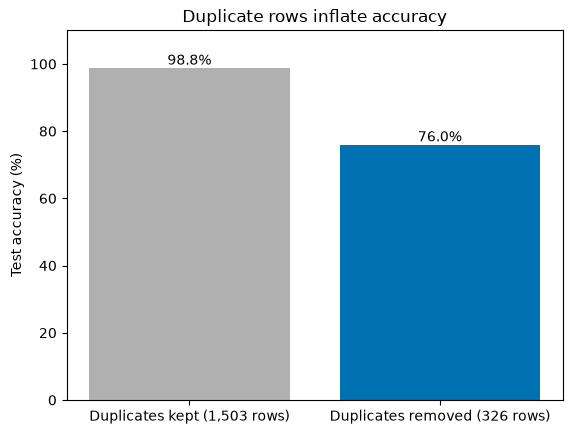

In [ ]:
# Task 32: Figure - effect of duplicate rows on accuracy
bars = plt.bar(leakage.index, leakage.values * 100, color=[GREY, BLUE])
plt.bar_label(bars, fmt="%.1f%%")
plt.ylim(0, 110)
plt.ylabel("Test accuracy (%)")
plt.title("Duplicate rows inflate accuracy")
plt.savefig(RESULTS_FOLDER / "fig07_leakage.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Task 33: Explainable AI - train the proposed model on 80% and keep 20% unseen to explain
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
final_model = hybrid_ensemble().fit(X_train, y_train)

In [ ]:
# Task 34: Turn answers into numbers for SHAP and LIME (0, 1, 2, ...)
fill_values = X_train.mode().iloc[0]
X_train_filled, X_test_filled = X_train.fillna(fill_values), X_test.fillna(fill_values)

encoder = OrdinalEncoder().fit(X.fillna(fill_values))
train_codes = encoder.transform(X_train_filled)
test_codes = encoder.transform(X_test_filled)

FEATURES = ["Age", "Sad / tearful", "Irritable", "Sleep trouble", "Concentration",
            "Appetite", "Guilt", "Bonding", "Suicide item"]

In [ ]:
# Task 35: Prediction function that SHAP and LIME can call (numbers in, probabilities out)
def predict_from_codes(codes):
    answers_text = pd.DataFrame(encoder.inverse_transform(np.round(codes)), columns=X.columns)
    return final_model.predict_proba(answers_text)


def predict_anxious(codes):
    return predict_from_codes(codes)[:, 1]

In [ ]:
# Task 36: SHAP values for every test respondent
start = time.time()
background = shap.utils.sample(train_codes, 50, random_state=SEED)
masker = shap.maskers.Independent(background)
shap_explainer = shap.Explainer(predict_anxious, masker, algorithm="exact", feature_names=FEATURES)
shap_result = shap_explainer(test_codes, silent=True)
shap_result.display_data = X_test_filled.to_numpy()          # show answers as text in the plots
shap_seconds = time.time() - start

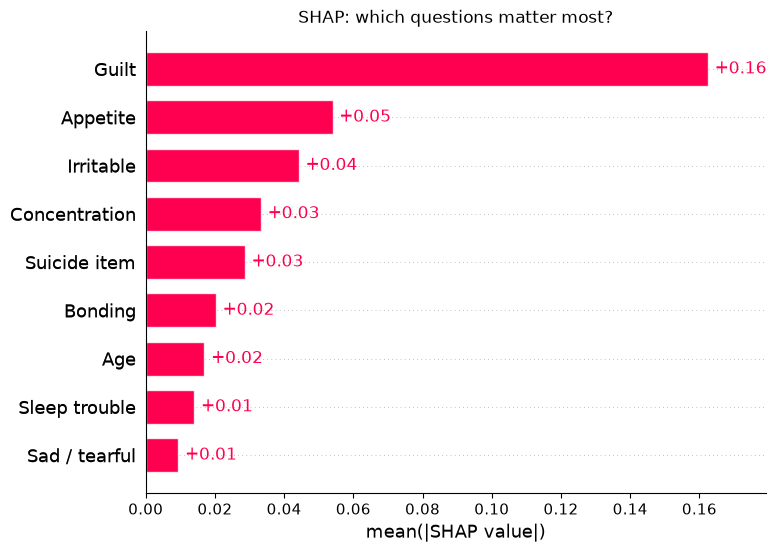

In [ ]:
# Task 37: Figure - SHAP global importance
shap.plots.bar(shap_result, max_display=9, show=False)
plt.title("SHAP: which questions matter most?")
plt.savefig(RESULTS_FOLDER / "fig08_shap_importance.png", dpi=300, bbox_inches="tight")
plt.show()

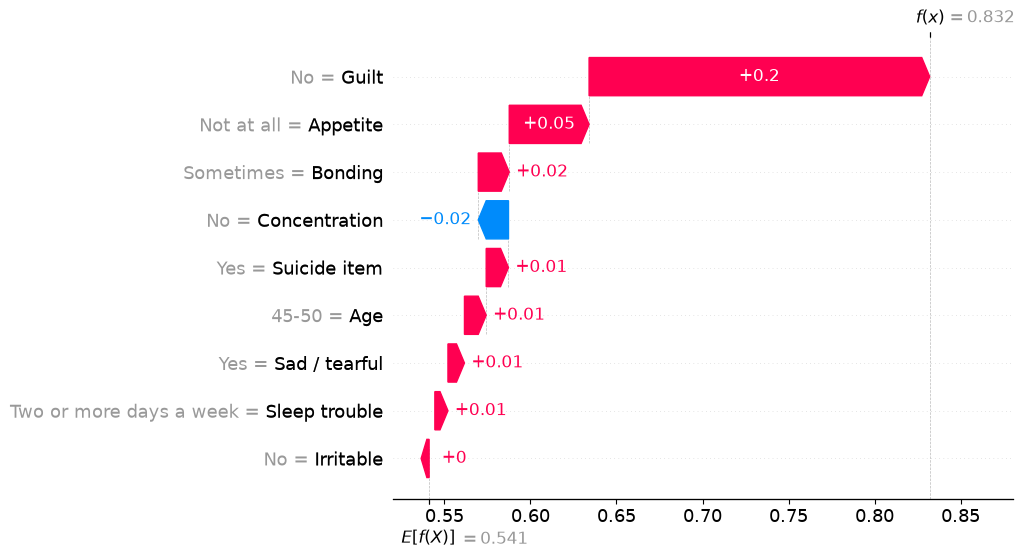

In [ ]:
# Task 38: Figure - SHAP explanation for one respondent (first anxious respondent in the test set)
person = int(np.where(y_test == 1)[0][0])
shap.plots.waterfall(shap_result[person], max_display=9, show=False)
plt.savefig(RESULTS_FOLDER / "fig09_shap_one_person.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Task 39: LIME explanations for every test respondent
start = time.time()
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    train_codes, feature_names=FEATURES, class_names=["Not anxious", "Anxious"],
    categorical_features=list(range(9)),
    categorical_names=dict(enumerate(encoder.categories_)),
    discretize_continuous=False, random_state=SEED)

lime_explanations = []
for row in test_codes:
    explanation = lime_explainer.explain_instance(row, predict_from_codes, num_features=9, num_samples=2000)
    lime_explanations.append(explanation)
lime_seconds = time.time() - start

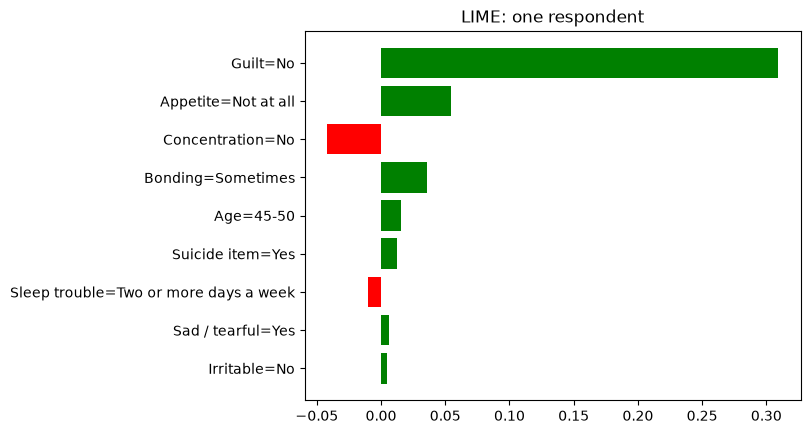

In [ ]:
# Task 40: Figure - LIME explanation for the same respondent
lime_explanations[person].as_pyplot_figure(label=1)
plt.title("LIME: one respondent")
plt.savefig(RESULTS_FOLDER / "fig10_lime_one_person.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Task 41: Collect the LIME weights in a table (one row per respondent, one column per question)
lime_values = np.zeros_like(test_codes)
for i, explanation in enumerate(lime_explanations):
    for feature, weight in explanation.as_map()[1]:
        lime_values[i, feature] = weight

In [ ]:
# Task 42: SHAP vs LIME - importance of each question (% of total)
shap_importance = np.abs(shap_result.values).mean(axis=0)
lime_importance = np.abs(lime_values).mean(axis=0)

importance = pd.DataFrame({
    "SHAP (%)": 100 * shap_importance / shap_importance.sum(),
    "LIME (%)": 100 * lime_importance / lime_importance.sum(),
}, index=FEATURES).round(1).sort_values("SHAP (%)", ascending=False)
importance.to_csv(RESULTS_FOLDER / "shap_vs_lime_importance.csv")
importance

,SHAP (%),LIME (%)
Guilt,42.4,47.6
Appetite,14.1,13.4
Irritable,11.5,10.4
Concentration,8.7,7.7
Suicide item,7.5,8.4
Bonding,5.3,5.0
Age,4.4,3.9
Sleep trouble,3.7,2.2
Sad / tearful,2.5,1.3


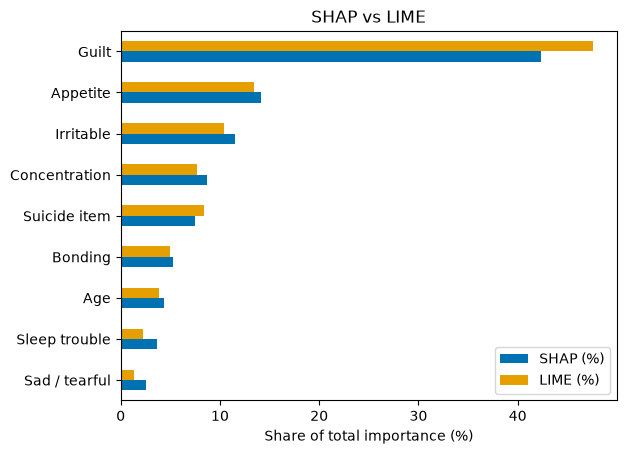

In [ ]:
# Task 43: Figure - SHAP vs LIME importance side by side
importance.sort_values("SHAP (%)").plot.barh(color=[BLUE, "#E69F00"])
plt.xlabel("Share of total importance (%)")
plt.title("SHAP vs LIME")
plt.savefig(RESULTS_FOLDER / "fig11_shap_vs_lime.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Task 44: SHAP vs LIME - how well do they agree, and how fast are they?
shap_top3 = list(importance.index[:3])
lime_top3 = list(importance.sort_values("LIME (%)", ascending=False).index[:3])

same_top_question = 0
person_agreement = []
for i in range(len(test_codes)):
    shap_row = np.abs(shap_result.values[i])
    lime_row = np.abs(lime_values[i])
    if shap_row.argmax() == lime_row.argmax():
        same_top_question += 1
    person_agreement.append(spearmanr(shap_row, lime_row)[0])

xai_comparison = pd.Series({
    "Global rank agreement (Spearman)": spearmanr(shap_importance, lime_importance)[0],
    "Same top-3 questions (out of 3)": len(set(shap_top3) & set(lime_top3)),
    "Per-person rank agreement (mean Spearman)": np.nanmean(person_agreement),
    "Same most important question per person (%)": 100 * same_top_question / len(test_codes),
    "SHAP time per person (s)": shap_seconds / len(test_codes),
    "LIME time per person (s)": lime_seconds / len(test_codes),
}).round(3)
xai_comparison.to_csv(RESULTS_FOLDER / "shap_vs_lime_agreement.csv")
xai_comparison

Global rank agreement (Spearman)                0.983
Same top-3 questions (out of 3)                 3.000
Per-person rank agreement (mean Spearman)       0.734
Same most important question per person (%)    84.848
SHAP time per person (s)                        0.412
LIME time per person (s)                        0.077
dtype: float64

In [ ]:
# Task 45: Final comparison 1 - model performance (for the thesis)
final_models = (test_results * 100).round(1)
final_models["mcc"] = test_results["mcc"]
final_models["roc_auc"] = test_results["roc_auc"]
final_models["train-test gap"] = (train_test["gap"] * 100).round(1)
final_models["rank"] = ranking["rank"]
final_models = final_models.sort_values("rank")
final_models.to_csv(RESULTS_FOLDER / "final_model_comparison.csv")
final_models

,balanced_accuracy,accuracy,sensitivity,specificity,f1,mcc,roc_auc,train-test gap,rank
model,,,,,,,,,
Hybrid Ensemble (proposed),77.2,78.5,85.4,69.0,82.1,0.558,0.843,10.2,1.75
Random Forest,77.1,78.5,86.1,68.1,82.3,0.558,0.843,7.5,2.25
Extra Trees,76.0,77.0,82.5,69.5,80.6,0.529,0.848,17.1,2.50
SVM,76.7,78.1,85.3,68.0,81.8,0.549,0.822,9.6,3.50
Logistic Regression,73.0,74.5,82.1,63.9,78.8,0.473,0.800,4.5,5.00


In [ ]:
# Task 46: Final comparison 2 - SHAP vs LIME (for the thesis)
final_xai = pd.DataFrame({
    "SHAP": ["Exact Shapley values", shap_top3[0], ", ".join(shap_top3),
             round(shap_seconds / len(test_codes), 2)],
    "LIME": ["Local linear approximation", lime_top3[0], ", ".join(lime_top3),
             round(lime_seconds / len(test_codes), 2)],
}, index=["Method", "Most important question", "Top 3 questions", "Seconds per person"])
final_xai.to_csv(RESULTS_FOLDER / "final_shap_vs_lime.csv")
final_xai

,SHAP,LIME
Method,Exact Shapley values,Local linear approximation
Most important question,Guilt,Guilt
Top 3 questions,"Guilt, Appetite, Irritable","Guilt, Appetite, Irritable"
Seconds per person,0.41,0.08


In [ ]:
# Task 47: Final comparison 3 - this study and related studies (different data: context only)
literature = pd.DataFrame([
    ["Nayee et al. 2026", "Kaggle, 1,503 rows (likely this dataset)", "Accuracy 96.99%"],
    ["This study, duplicates kept", "Same 1,503 rows", "Accuracy " + str(round(100 * leakage.iloc[0], 1)) + "%"],
    ["This study, duplicates removed", "326 unique rows", "Accuracy " + str(round(100 * leakage.iloc[1], 1)) + "%"],
    ["This study, Hybrid Ensemble", "326 unique rows, 50-fold CV",
     "Balanced accuracy " + str(round(100 * test_results.loc[PROPOSED, "balanced_accuracy"], 1))
     + "%, AUC " + str(test_results.loc[PROPOSED, "roc_auc"])],
    ["Zhang et al. 2020", "Chinese cohort, 508 women", "AUC 0.78"],
    ["Nakamura et al. 2024", "Japanese cohort", "AUC 0.83"],
    ["Amit et al. 2021", "UK health records, 266,544 women", "AUC 0.72-0.74"],
    ["Adhikari & Karki 2026", "Bangladesh, 800 women", "Accuracy 76.5-77.4%"],
], columns=["study", "data", "reported result"])
literature.to_csv(RESULTS_FOLDER / "final_literature_comparison.csv", index=False)
literature

,study,data,reported result
0,Nayee et al. 2026,"Kaggle, 1,503 rows (likely this dataset)",Accuracy 96.99%
1,"This study, duplicates kept","Same 1,503 rows",Accuracy 98.8%
2,"This study, duplicates removed",326 unique rows,Accuracy 76.0%
3,"This study, Hybrid Ensemble","326 unique rows, 50-fold CV","Balanced accuracy 77.2%, AUC 0.843"
4,Zhang et al. 2020,"Chinese cohort, 508 women",AUC 0.78
5,Nakamura et al. 2024,Japanese cohort,AUC 0.83
6,Amit et al. 2021,"UK health records, 266,544 women",AUC 0.72-0.74
7,Adhikari & Karki 2026,"Bangladesh, 800 women",Accuracy 76.5-77.4%
